In [9]:
##Partie 1 : Introduction au Dataset

# 1. Téléchargement du dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = sns.load_dataset('titanic')

## séparation des donées avant le nettoyage

X= df.drop('survived', axis=1)
Y= df['survived']

X_train, X_test, Y_train, Y_test = train_test_split( X, Y, test_size=0.2, shuffle= False )



print('la forme de X_train ', X_train.shape)
print('la forme de Y_train ', Y_train.shape)
print('la forme de X_test  ', X_test.shape)
print('la forme de Y_test  ', Y_test.shape)

la forme de X_train  (712, 14)
la forme de Y_train  (712,)
la forme de X_test   (179, 14)
la forme de Y_test   (179,)


In [10]:
# Analyse du dataset
print("--- Types de données ---")
print(X_train.dtypes)

print("\n--- Premières lignes du dataset ---")
display(X_train.head(20))

print("\n--- Valeurs manquantes par colonne (train) ---")
print(X_train.isnull().sum())

print("\n--- Valeurs manquantes par colonne test ---")
print(X_test.isnull().sum())


--- Types de données ---
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

--- Premières lignes du dataset ---


,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False



--- Valeurs manquantes par colonne (train) ---
pclass           0
sex              0
age            147
sibsp            0
parch            0
fare             0
embarked         1
class            0
who              0
adult_male       0
deck           551
embark_town      1
alive            0
alone            0
dtype: int64

--- Valeurs manquantes par colonne test ---
pclass           0
sex              0
age             30
sibsp            0
parch            0
fare             0
embarked         1
class            0
who              0
adult_male       0
deck           137
embark_town      1
alive            0
alone            0
dtype: int64


In [11]:
##Partie 2 : Nettoyage des Données

# 1. Gestion des valeurs manquantes


#missing_Values =  X_train.isnull().mean()*100
#print("Pourcentage de valeurs manquantes : \n ", missing_Values )

def remplacez(X_train, X_test, seuil_sippression = 40 ):
    
    missing_Values =  X_train.isnull().mean()*100
    print("Pourcentage de valeurs manquantes 'avant' : \n ", missing_Values )

    for col in missing_Values.index:
     
      if missing_Values[col] > seuil_sippression:
        X_train.drop(columns=[col] , inplace= True )
        X_test.drop(columns=[col] , inplace= True )
    
    for col in X_train.columns:

      if X_train[col].isnull().sum()>0:
            
        if isinstance(X_train[col].dtype,pd.CategoricalDtype) :
          X_train[col] = X_train[col].astype(object)
          X_train[col] = X_test[col].astype(object)
 
        if pd.api.types.is_numeric_dtype(X_train[col]):
            valeur = X_train[col].median()
        else:
            valeur = X_train[col].mode()[0] 
        X_train[col] =  X_train[col].fillna(valeur )
        X_test[col] = X_test[col].fillna(valeur )

    missing_Values =  X_train.isnull().mean()*100
    print("Pourcentage de valeurs manquantes'apres nettoyage' : \n ", missing_Values )     
    return X_train, X_test

In [12]:
X_train, X_test = remplacez(X_train, X_test)

Pourcentage de valeurs manquantes 'avant' : 
  pclass          0.000000
sex             0.000000
age            20.646067
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.140449
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.387640
embark_town     0.140449
alive           0.000000
alone           0.000000
dtype: float64
Pourcentage de valeurs manquantes'apres nettoyage' : 
  pclass         0.0
sex            0.0
age            0.0
sibsp          0.0
parch          0.0
fare           0.0
embarked       0.0
class          0.0
who            0.0
adult_male     0.0
embark_town    0.0
alive          0.0
alone          0.0
dtype: float64


In [13]:
X_train.head()

,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


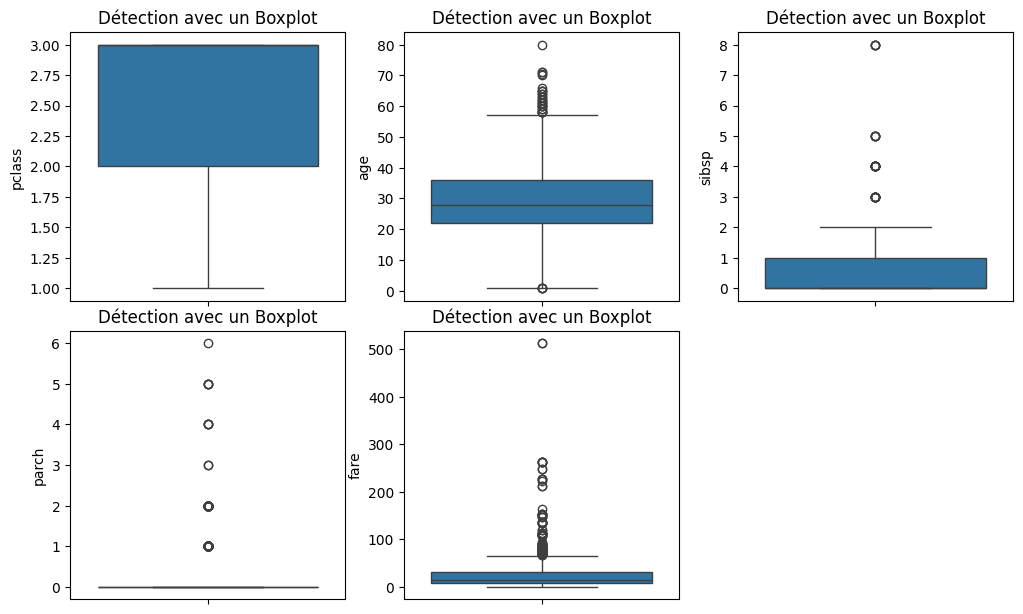

In [14]:
# 2. Gestion des valeurs aberrantes
    ## Détection avec un Boxplot

import math

col_num = X_train.select_dtypes(include=[np.number]).columns
n_row = math.ceil(len(col_num)/3)
n_col= 3
plt.figure(figsize=(10, 3 * n_row))

for i, col in enumerate(col_num) :

    plt.subplot(n_row, n_col, i+1)
    sns.boxplot(X_train[col])
    plt.title(f'Détection avec un Boxplot')

plt.tight_layout(pad=0.2)
plt.show()
    




In [15]:
for col in ['age', 'fare']:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    median = X_train[col].median()

    X_train[col] = np.where((X_train[col]< lower) | (X_train[col]>upper) , median, X_train[col])
    X_test[col] = np.where((X_test[col]< lower) | (X_test[col]>upper) , median, X_test[col])



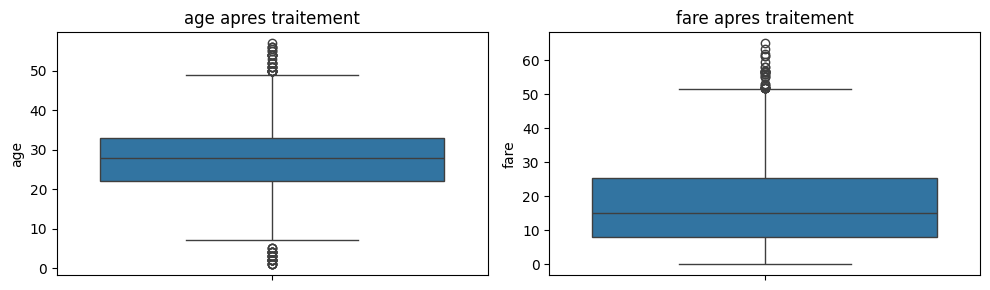

In [16]:

plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
sns.boxplot(X_train['age'])
plt.title(f'age apres traitement')

plt.subplot(1, 2, 2)
sns.boxplot(X_train['fare'])
plt.title(f'fare apres traitement')

plt.tight_layout()
plt.show()

In [17]:
## Partie 3 : Transformation des Données

#1. Encodage des variables catégorielles

print('les colonnes catégorielles :')
print(X_train.select_dtypes(include=['object','category','bool']).columns.tolist())

les colonnes catégorielles :
['sex', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive', 'alone']


In [18]:
def encodage(X_train, X_test):

##1.ordinal
    class_D = {'First':1, 'Second':2, 'Third':3 }
    X_train['class']= X_train['class'].astype(str).map(class_D)
    X_test['class']= X_test['class'].astype(str).map(class_D)

##2.bool
    for col in ['adult_male', 'alone']:
        X_train[col]= X_train[col].astype(int)
        X_test[col]= X_test[col].astype(int)

##3.Nominal
    cols_nominal= ['sex','embarked','who','embark_town','alive']
    X_train = pd.get_dummies(X_train, columns= cols_nominal, drop_first= True, dtype= int)
    X_test =  pd.get_dummies(X_test, columns= cols_nominal, drop_first= True, dtype= int)

    X_test = X_test.reindex(columns=X_train.columns, fill_value= 0)

    return X_train, X_test


In [19]:
X_train, X_test = encodage(X_train, X_test)
print(X_train.shape)
print(X_train.columns.tolist())

(712, 16)
['pclass', 'age', 'sibsp', 'parch', 'fare', 'class', 'adult_male', 'alone', 'sex_male', 'embarked_Q', 'embarked_S', 'who_man', 'who_woman', 'embark_town_Queenstown', 'embark_town_Southampton', 'alive_yes']


In [20]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler


#--Normalisation Min-Max[0,1]--

scaler_norm = MinMaxScaler()
X_train_norm = X_train.copy()
X_tset_norm = X_test.copy()
X_train_norm[col_num] = scaler_norm.fit_transform(X_train[col_num])
X_tset_norm[col_num] = scaler_norm.fit_transform(X_test[col_num])

#--Standardisation Z-score [moyenne 0, ecart-type 1] --

scaler_std = StandardScaler()
X_train_std = X_train.copy()
X_tset_std = X_test.copy()
X_train_std[col_num] = scaler_std.fit_transform(X_train[col_num])
X_tset_std[col_num] = scaler_std.transform(X_test[col_num])

print('avant-fare', round(X_train['fare'].min(),1) , 'max',round(X_train['fare'].max(),1),round(X_train['fare'].mean(),1) )
print('Min-Max-fare', round(X_train_norm['fare'].min(),2) , 'max',round(X_train_norm['fare'].max(),2))
print('z-score-fare', round(X_train_std['fare'].mean(),2) , 'max',round(X_train_std['fare'].std(),2))


avant-fare 0.0 max 65.0 17.6
Min-Max-fare 0.0 max 1.0
z-score-fare 0.0 max 1.0


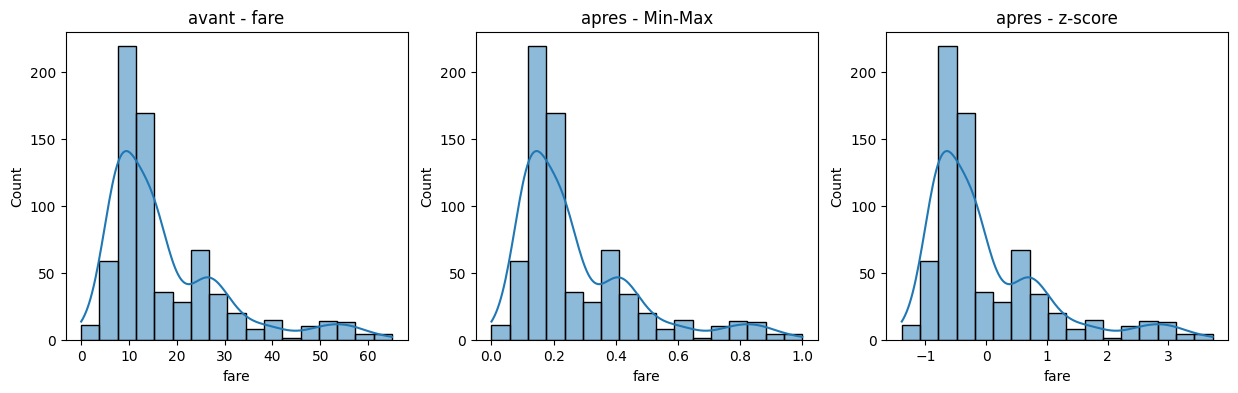

In [21]:
plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
sns.histplot(X_train['fare'], kde=True)
plt.title('avant - fare')

plt.subplot(1,3,2)
sns.histplot(X_train_norm['fare'], kde=True)
plt.title('apres - Min-Max')

plt.subplot(1,3,3)
sns.histplot(X_train_std['fare'], kde=True)
plt.title('apres - z-score')

plt.show()


survived
0    434
1    278
Name: count, dtype: int64
survived
0    60.955056
1    39.044944
Name: proportion, dtype: float64


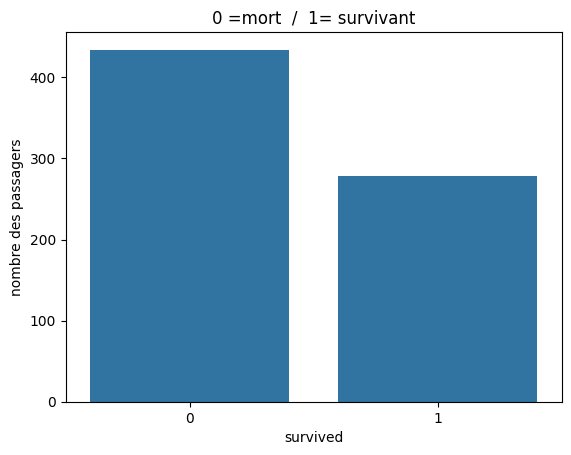

In [22]:
#Partie 4 : Gestion des Données Déséquilibrées
##1. Identification du déséquilibre des classes

print(Y_train.value_counts())
print(Y_train.value_counts(normalize= True)*100)
sns.countplot(x=Y_train)
plt.title('0 =mort  /  1= survivant')
plt.ylabel('nombre des passagers')
plt.show()


In [23]:
import sys
!{sys.executable} -m pip install imbalanced-learn

aprés undersampling
survived
0    278
1    278
Name: count, dtype: int64
aprés SMOTE
survived
0    434
1    434
Name: count, dtype: int64


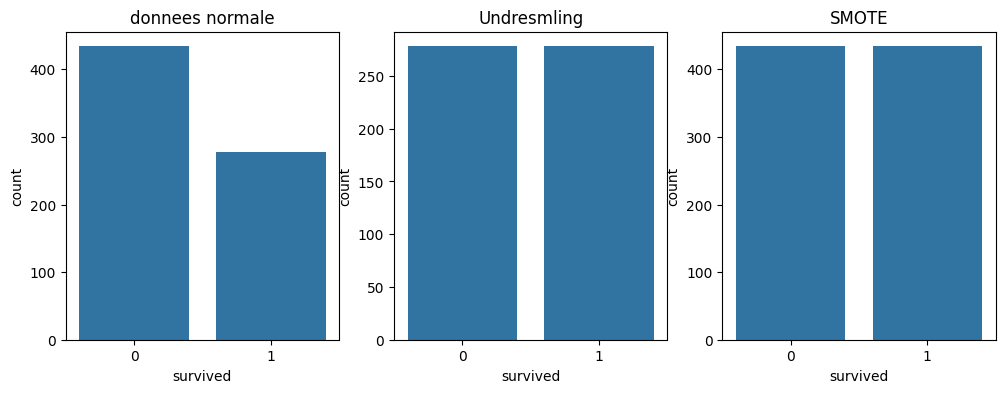

In [27]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

# Undersampling
rus = RandomUnderSampler(random_state=42)
X_under, Y_under = rus.fit_resample(X_train, Y_train)
print('aprés undersampling')
print(Y_under.value_counts())

# SMOTE
smote = SMOTE(random_state=42)
X_train_res, Y_train_res = smote.fit_resample(X_train, Y_train)
print('aprés SMOTE')
print(Y_train_res.value_counts())


plt.figure(figsize=(12,4))
plt.subplot(1,3,1); sns.countplot(x=Y_train); plt.title('donnees normale')
plt.subplot(1,3,2); sns.countplot(x=Y_under); plt.title('Undresmling')
plt.subplot(1,3,3); sns.countplot(x=Y_train_res); plt.title('SMOTE')

plt.show()

